# 01 · Student’s vs Welch’s: is the difference real?
**Key difference: unequal variability.** Student’s pools the groups’ variances; Welch’s estimates their contributions separately. Unequal sample sizes make this distinction especially consequential.

We simulate delivery times with **equal true means (60 minutes)**. Any significant result is therefore a false positive. These are illustrative normal populations, not observed deliveries; their negligible negative tail is retained to preserve the normal model.

### Assumptions in brief
Both tests compare two independent population means, using independent numerical observations. Here populations are normal by construction. Student’s additionally assumes equal population variances; Welch’s does not. Neither requires equal sample sizes. All tests are two-sided at 5%.

One sample illustrates the setup; repeated samples measure reliability. No sample is selected for disagreement.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 20261125
REPETITIONS = 20_000
ALPHA = 0.05
OUT = Path("outputs/01-student-vs-welch")
OUT.mkdir(parents=True, exist_ok=True)
scenarios = [
    dict(scenario="1 · Equal variability", n_a=50, n_b=50, sd_a=5, sd_b=5),
    dict(scenario="2 · Unequal variability", n_a=20, n_b=100, sd_a=15, sd_b=5),
]
display(pd.DataFrame(scenarios).assign(mean_a=60, mean_b=60))

,scenario,n_a,n_b,sd_a,sd_b,mean_a,mean_b
0,1 · Equal variability,50,50,5,5,60,60
1,2 · Unequal variability,20,100,15,5,60,60


## 1 · See the two datasets
Scenario 1 is a baseline where both tests should agree. In scenario 2, the **smaller group has the larger spread**. Both sample size and spread change between scenarios, so this is a demonstration of their combined effect, not an isolated estimate of the effect of variance alone.

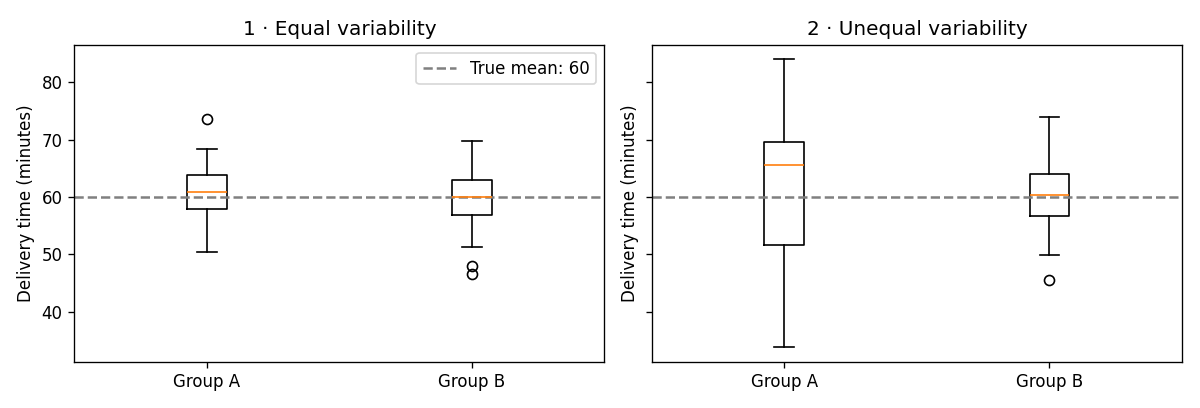

In [2]:
example_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
example_rows = []
for ax, s in zip(axes, scenarios):
    a = example_rng.normal(60, s["sd_a"], s["n_a"])
    b = example_rng.normal(60, s["sd_b"], s["n_b"])
    ax.boxplot([a, b], tick_labels=["Group A", "Group B"])
    ax.axhline(60, color="gray", linestyle="--", label="True mean: 60")
    ax.set_title(s["scenario"])
    ax.set_ylabel("Delivery time (minutes)")
    for group, values in [("A", a), ("B", b)]:
        example_rows.extend(dict(scenario=s["scenario"], group=group, minutes=x) for x in values)
axes[0].legend()
fig.tight_layout()
fig.savefig(OUT / "example_samples.png", dpi=160)
plt.show()
pd.DataFrame(example_rows).to_csv(OUT / "example_samples.csv", index=False)

## 2 · Repeat fairly and measure false alarms
Run both tests on **the same samples** in each repetition. Primary metric: false-positive rate (target: 5%). Also report its 95% Wilson Monte Carlo interval, average estimated standard error, and the known true standard error of the difference. Monte Carlo intervals quantify simulation noise, not real-world validity.

In [3]:
rng = np.random.default_rng(SEED + 1)
rows, trial_frames = [], []
for s in scenarios:
    a = rng.normal(60, s["sd_a"], (REPETITIONS, s["n_a"]))
    b = rng.normal(60, s["sd_b"], (REPETITIONS, s["n_b"]))
    va, vb = a.var(axis=1, ddof=1), b.var(axis=1, ddof=1)
    pooled_var = ((s["n_a"]-1)*va + (s["n_b"]-1)*vb) / (s["n_a"]+s["n_b"]-2)
    standard_errors = {
        "Student": np.sqrt(pooled_var * (1/s["n_a"] + 1/s["n_b"])),
        "Welch": np.sqrt(va/s["n_a"] + vb/s["n_b"]),
    }
    true_se = np.sqrt(s["sd_a"]**2/s["n_a"] + s["sd_b"]**2/s["n_b"])
    for test, equal_var in [("Student", True), ("Welch", False)]:
        result = stats.ttest_ind(a, b, axis=1, equal_var=equal_var)
        rejected = result.pvalue < ALPHA
        count = int(rejected.sum())
        interval = stats.binomtest(count, REPETITIONS).proportion_ci(method="wilson")
        ci = result.confidence_interval(confidence_level=1-ALPHA)
        coverage = np.mean((ci.low <= 0) & (ci.high >= 0))
        rows.append(dict(scenario=s["scenario"], test=test, repetitions=REPETITIONS,
            false_positives=count, false_positive_pct=100*rejected.mean(),
            mc_low_pct=100*interval.low, mc_high_pct=100*interval.high,
            mean_estimated_se=standard_errors[test].mean(), true_se=true_se,
            coverage_pct=100*coverage))
        trial_frames.append(pd.DataFrame(dict(scenario=s["scenario"], test=test,
            repetition=np.arange(REPETITIONS), mean_difference=a.mean(axis=1)-b.mean(axis=1),
            p_value=result.pvalue)))
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "metrics.csv", index=False)
pd.concat(trial_frames, ignore_index=True).to_csv(OUT / "trials.csv", index=False)
display(summary.round(3))
assert np.isfinite(summary.select_dtypes("number")).all().all()
assert np.allclose(summary.false_positive_pct + summary.coverage_pct, 100)
assert np.isclose(summary.iloc[0].mean_estimated_se, summary.iloc[1].mean_estimated_se)


,scenario,test,repetitions,false_positives,false_positive_pct,mc_low_pct,mc_high_pct,mean_estimated_se,true_se,coverage_pct
0,1 · Equal variability,Student,20000,1041,5.205,4.906,5.522,0.997,1.000,94.795
1,1 · Equal variability,Welch,20000,1041,5.205,4.906,5.522,0.997,1.000,94.795
2,2 · Unequal variability,Student,20000,5614,28.070,27.452,28.697,1.842,3.391,71.930
3,2 · Unequal variability,Welch,20000,977,4.885,4.595,5.192,3.348,3.391,95.115


## 3 · The comparison
The dashed line is the intended false-alarm rate. Error bars show 95% Monte Carlo intervals. Confidence-interval coverage in the table is complementary to rejection here, not independent evidence.

1 · Equal variability: Student 5.21%; Welch 5.21% false positives.
2 · Unequal variability: Student 28.07%; Welch 4.88% false positives.
Out[1]: 532


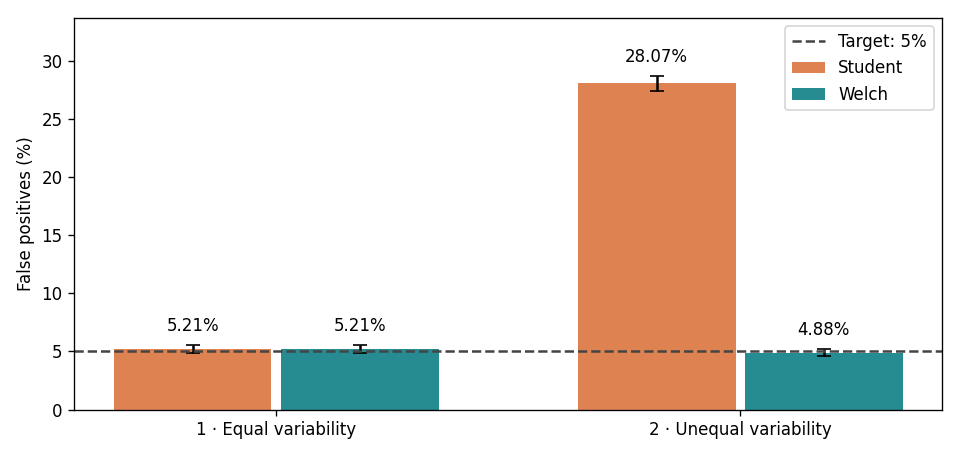

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(scenarios))
for test, offset, color in [("Student", -0.18, "#df8252"), ("Welch", 0.18, "#268c91")]:
    data = summary[summary.test == test]
    rates = data.false_positive_pct.to_numpy()
    errors = np.vstack([rates-data.mc_low_pct.to_numpy(), data.mc_high_pct.to_numpy()-rates])
    bars = ax.bar(x+offset, rates, width=0.34, label=test, color=color, yerr=errors, capsize=4)
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in rates], padding=6)
ax.axhline(5, linestyle="--", color="#444444", label="Target: 5%")
ax.set_xticks(x, [s["scenario"] for s in scenarios])
ax.set_ylabel("False positives (%)")
ax.set_ylim(0, summary.mc_high_pct.max()+5)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "false_positive_rates.png", dpi=180)
plt.show()
for s in scenarios:
    data = summary[summary.scenario == s["scenario"]].set_index("test")
    print(f'{s["scenario"]}: Student {data.loc["Student", "false_positive_pct"]:.2f}%; '
          f'Welch {data.loc["Welch", "false_positive_pct"]:.2f}% false positives.')
settings = dict(seed=SEED, simulation_seed=SEED+1, repetitions=REPETITIONS, alpha=ALPHA,
    population_means=[60, 60], distribution="normal", scenarios=scenarios,
    python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, pandas=pd.__version__)
(OUT / "settings.json").write_text(json.dumps(settings, indent=2))

## Takeaway · Why Welch’s helps
**Equal variability:** both methods stay near the intended 5% false-positive rate.

**Unequal variability + unequal sizes:** the large, low-variance group dominates Student’s pooled variance. This understates uncertainty for the small, noisy group and produces too many false positives. Welch’s accounts for each group’s variance and stays near 5%.

For scenario 2, the true SE is √(225/20 + 25/100) ≈ **3.39 minutes**; compare this with each test’s average estimated SE above. Welch’s also adjusts the degrees of freedom.

**Scope:** this measures false alarms under equal means, not power to detect a real change. Reversing which group has greater variance can make Student’s conservative. Normality and independence are preserved here; Welch’s does not fix dependence or every outlier problem. Multiple-comparison corrections are a later notebook: these repetitions estimate a single-test error rate, rather than searching for one reportable discovery.

**Review prompt:** Why does giving the noisy group fewer observations make pooling the variances especially misleading?

## Website presentation brief

**Goal:** one clear statistical insight at a time, shown visually, with just enough explanation to understand why. Keep the main story compact; make assumptions and technical detail available as optional deeper reading. This is presentation guidance for a future website, not an implemented page.

### Story flow
1. **Question:** “Can a test find a difference when there isn’t one?” Establish that both simulated delivery-time populations have a true mean of 60 minutes.
2. **Setup:** Show the two groups side by side, with sample sizes and population SDs clearly labelled. Start with equal variability and equal sizes, then reveal the smaller, noisier group in scenario 2. Separate known population settings from the observed example sample.
3. **Visual evidence:** Lead with the false-positive-rate chart, consistent colours for Student’s and Welch’s, direct percentage labels, and a prominent 5% target line. Explain: “We repeated each scenario 20,000 times. Every detected difference here is a false alarm.” Keep Monte Carlo intervals visible, with their meaning in optional detail.
4. **Why it happens:** Student’s pools the variance estimates; the larger, steadier group pulls that estimate down. Welch’s accounts for each group’s variability separately. Use the estimated-versus-true standard errors as supporting evidence, rather than leading with formulas.
5. **Takeaway:** “When the smaller group is noisier, Student’s can produce too many false alarms; Welch’s accounts for that unequal variability.”

### Presentation boundaries
- Highlight **unequal variability**, while making clear that unequal group sizes amplify its effect here. Both change between scenarios; this is not an isolated variance experiment.
- Use the saved metrics for displayed values; do not hard-code rounded results independently of the data. Both methods perform similarly in the baseline, and Welch’s stays near the intended false-alarm rate in the second scenario.
- Explain what the chart measures: false positives under equal means, not power, the probability that a particular finding is false, or evidence about real delivery services.
- Keep normality, independence, two-sided testing, and the 5% threshold in a compact assumptions panel. Detailed formulas, simulation settings, and uncertainty belong in expandable detail.
- Optional interaction: switch between the two scenarios without changing colours or the chart scale. No interaction is required to understand the main insight.

**Reusable direction for later comparisons:** question → setup → visual evidence → explanation → takeaway. Choose fair comparisons that reveal when and why methods differ, rather than presenting a universal winning test.
